# Les jeunes sont-ils réellement plus inquiets du changement climatique, et est-ce que ça se traduit en comportements ?

**Données :** European Social Survey, vague 8 (2016), sous-ensemble fourni — 44 387 répondants, 23 pays.

**Démarche :**
1. Préparation des données (recodages, groupes d'âge, pondération).
2. **Inquiétude** : les jeunes (15-29 ans) sont-ils plus inquiets que leurs aînés ? Et en matière de perception (cause humaine, responsabilité personnelle) ?
3. **Comportements** : économies d'énergie, achats, engagement politique (pétition, manifestation, boycott), soutien aux politiques climatiques.
4. **Lien inquiétude → comportement** : l'inquiétude se traduit-elle en actes, et ce lien est-il différent chez les jeunes ?

Les statistiques descriptives sont pondérées par `anweight` (poids d'analyse recommandé par l'ESS pour comparer plusieurs pays). Les régressions incluent des effets fixes pays.

In [1]:
import numpy as np
import pandas as pd
import pyreadstat
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from pathlib import Path

pd.set_option('display.float_format', '{:.3f}'.format)
FIG = Path('figures'); FIG.mkdir(exist_ok=True)

# Palette (bleu = jeunes, gris = reste de la population)
BLUE, ORANGE, AQUA, GREY, TXT, TXT2 = '#257de0', '#f47230', '#00b894', '#9a9a9a', '#191919', '#666666'
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.edgecolor': '#cccccc',
    'axes.labelcolor': TXT2, 'xtick.color': TXT2, 'ytick.color': TXT2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': '#eeeeee', 'grid.linewidth': 0.8,
    'axes.titleweight': 'bold', 'axes.titlesize': 11, 'axes.titlelocation': 'left',
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
})

## 1. Chargement et préparation des données

In [2]:
cols = ['cntry', 'anweight', 'agea', 'gndr', 'eduyrs', 'mnactic',
        'wrclmch', 'ccrdprs', 'ccnthum',                       # perception
        'rdcenr', 'eneffap',                                   # comportements énergie
        'sgnptit', 'pbldmn', 'bctprd',                         # engagement politique
        'inctxff', 'sbsrnen', 'banhhap']                       # soutien aux politiques
df, meta = pyreadstat.read_sav('data/ESS8e02_3-subset.sav', usecols=cols)
print(df.shape)
df.head()

(44387, 17)


,cntry,anweight,sgnptit,pbldmn,bctprd,eneffap,rdcenr,ccnthum,ccrdprs,wrclmch,inctxff,sbsrnen,banhhap,gndr,agea,eduyrs,mnactic
0,AT,0.437,1.000,2.000,1.000,8.000,4.000,4.000,8.000,4.000,1.000,1.000,2.000,2.000,34.000,21.000,2.000
1,AT,0.333,2.000,2.000,1.000,10.000,5.000,4.000,7.000,4.000,1.000,2.000,2.000,1.000,52.000,16.000,1.000
2,AT,0.117,2.000,2.000,1.000,9.000,4.000,4.000,8.000,4.000,4.000,2.000,2.000,2.000,68.000,13.000,6.000
3,AT,0.175,2.000,2.000,2.000,10.000,4.000,3.000,6.000,3.000,3.000,3.000,3.000,1.000,54.000,12.000,1.000
4,AT,0.832,2.000,2.000,2.000,10.000,6.000,4.000,6.000,4.000,3.000,1.000,4.000,2.000,20.000,13.000,3.000


Les non-réponses (refus, ne sait pas…) sont déjà converties en `NaN` à la lecture. Il reste deux codes « hors échelle » à neutraliser :
- `rdcenr = 55` : « ne peut pas réduire sa consommation » ;
- `ccnthum = 55` : « je ne pense pas que le climat change ».

On construit ensuite des indicateurs binaires faciles à lire (en %).

In [3]:
df.loc[df.rdcenr == 55, 'rdcenr'] = np.nan
df.loc[df.ccnthum == 55, 'ccnthum'] = np.nan
df = df[df.agea.notna()].copy()

df['age_grp'] = pd.cut(df.agea, [14, 29, 44, 59, 74, 120],
                       labels=['15-29', '30-44', '45-59', '60-74', '75+'])
df['jeune'] = (df.agea < 30).astype(int)
df['femme'] = (df.gndr == 2).astype(int)
df['etudiant'] = (df.mnactic == 2).astype(int)

def binaire(cond, src):
    return cond.astype(float).where(df[src].notna())

# Perception
df['inquiet']      = binaire(df.wrclmch >= 4, 'wrclmch')   # très / extrêmement inquiet
df['cause_humaine']= binaire(df.ccnthum >= 4, 'ccnthum')   # principalement / entièrement humaine
df['responsable']  = binaire(df.ccrdprs >= 7, 'ccrdprs')   # responsabilité perso >= 7/10
# Comportements
df['eco_energie']  = binaire(df.rdcenr >= 4, 'rdcenr')     # souvent / très souvent / toujours
df['achat_eff']    = binaire(df.eneffap >= 8, 'eneffap')   # achat appareil efficace probable (>= 8/10)
df['petition']     = binaire(df.sgnptit == 1, 'sgnptit')
df['manif']        = binaire(df.pbldmn == 1, 'pbldmn')
df['boycott']      = binaire(df.bctprd == 1, 'bctprd')
# Soutien aux politiques (1-2 = plutôt / très favorable)
df['pour_taxe']    = binaire(df.inctxff <= 2, 'inctxff')
df['pour_subv']    = binaire(df.sbsrnen <= 2, 'sbsrnen')
df['pour_interd']  = binaire(df.banhhap <= 2, 'banhhap')

print(df.age_grp.value_counts().sort_index())

age_grp
15-29     8095
30-44    10477
45-59    11281
60-74    10170
75+       4209
Name: count, dtype: int64


In [4]:
def wmean(g, v):
    m = g[v].notna()
    return np.average(g.loc[m, v], weights=g.loc[m, 'anweight'])

def tableau(vars_, by='age_grp'):
    return pd.DataFrame({v: df.groupby(by, observed=True).apply(lambda g: wmean(g, v)) for v in vars_}).T

## 2. Les jeunes sont-ils plus inquiets ?

### 2.1 Comparaison par groupe d'âge (moyennes pondérées)
`wrclmch` : inquiétude de 1 (pas du tout) à 5 (extrêmement) ; `ccrdprs` : responsabilité personnelle de 0 à 10.

In [5]:
perc = tableau(['wrclmch', 'inquiet', 'ccrdprs', 'responsable', 'cause_humaine'])
perc

age_grp,15-29,30-44,45-59,60-74,75+
wrclmch,3.044,3.056,3.124,3.069,2.930
inquiet,0.294,0.294,0.313,0.299,0.268
ccrdprs,5.494,5.656,5.802,5.543,4.814
responsable,0.380,0.432,0.455,0.424,0.329
cause_humaine,0.522,0.486,0.459,0.404,0.379


In [6]:
# Distribution complète de l'inquiétude : jeunes vs 30 ans et plus
labels = ['Pas du tout', 'Pas très', 'Assez', 'Très', 'Extrêmement']
dist = (df.dropna(subset=['wrclmch'])
          .groupby(['jeune', 'wrclmch'])['anweight'].sum()
          .groupby(level=0).transform(lambda s: s / s.sum()).unstack())
dist.index = ['30 ans et +', '15-29 ans']; dist.columns = labels
(dist * 100).round(1)

,Pas du tout,Pas très,Assez,Très,Extrêmement
30 ans et +,5.500,18.000,46.600,23.900,6.000
15-29 ans,6.000,19.200,45.500,23.200,6.200


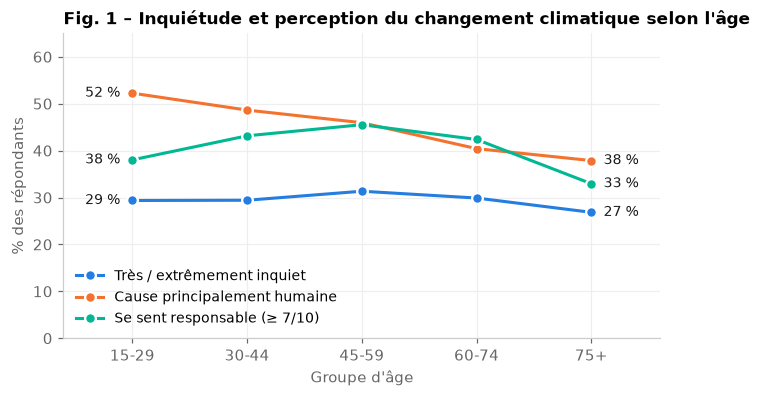

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(5)
series = [('inquiet', 'Très / extrêmement inquiet', BLUE),
          ('cause_humaine', 'Cause principalement humaine', ORANGE),
          ('responsable', 'Se sent responsable (≥ 7/10)', AQUA)]
for v, lab, col in series:
    y = perc.loc[v].values * 100
    ax.plot(x, y, color=col, lw=2, marker='o', ms=7, mec='white', mew=1.5, label=lab)
    ax.annotate(f'{y[0]:.0f} %', (x[0], y[0]), xytext=(-8, 0), textcoords='offset points',
                ha='right', va='center', color=TXT, fontsize=9)
    ax.annotate(f'{y[-1]:.0f} %', (x[-1], y[-1]), xytext=(8, 0), textcoords='offset points',
                ha='left', va='center', color=TXT, fontsize=9)
ax.set_xticks(x, perc.columns); ax.set_xlim(-0.6, 4.6); ax.set_ylim(0, 65)
ax.set_xlabel("Groupe d'âge"); ax.set_ylabel('% des répondants')
ax.set_title("Fig. 1 – Inquiétude et perception du changement climatique selon l'âge")
ax.legend(frameon=False, loc='lower left', fontsize=9)
fig.savefig(FIG / 'fig1_perception_age.png'); plt.show()

**Lecture :** l'inquiétude est remarquablement **stable avec l'âge** : environ 30 % des 15-29 ans se disent très ou extrêmement inquiets, soit autant que les 30-74 ans. Seuls les 75 ans et plus sont un peu moins inquiets. La responsabilité personnelle suit le même profil plat (légère bosse vers 45-59 ans).

En revanche, la **conviction que le changement climatique est d'origine humaine** décroît nettement avec l'âge : c'est là que les jeunes se distinguent vraiment.

### 2.2 Test : l'écart jeunes / aînés est-il significatif ?
Régression linéaire (MCO) avec contrôles (sexe, années d'études) et effets fixes pays, erreurs-types robustes. Le coefficient `jeune` mesure l'écart moyen entre les 15-29 ans et les 30 ans et plus, à pays, sexe et éducation comparables.

In [8]:
def effet_jeune(y, extra=''):
    r = smf.ols(f'{y} ~ jeune + femme + eduyrs + C(cntry){extra}', data=df).fit(cov_type='HC1')
    lo, hi = r.conf_int().loc['jeune']
    return pd.Series({'coef_jeune': r.params['jeune'], 'IC95_bas': lo, 'IC95_haut': hi,
                      'p_value': r.pvalues['jeune'], 'n': int(r.nobs)})

res_perc = pd.DataFrame({y: effet_jeune(y) for y in ['wrclmch', 'inquiet', 'ccrdprs', 'cause_humaine']}).T
res_perc

,coef_jeune,IC95_bas,IC95_haut,p_value,n
wrclmch,0.023,0.001,0.046,0.043,42159.000
inquiet,0.014,0.003,0.025,0.012,42159.000
ccrdprs,-0.021,-0.082,0.039,0.494,41465.000
cause_humaine,0.097,0.085,0.109,0.000,41430.000


L'écart d'inquiétude (`wrclmch`) est **minuscule** (de l'ordre de 0,02 point sur une échelle de 1 à 5) : statistiquement détectable grâce à la taille de l'échantillon, mais sans portée pratique. La responsabilité personnelle ne diffère pas. Par contre, les jeunes ont environ **10 points de % de plus** de chances d'attribuer le changement climatique à l'activité humaine.

### 2.3 Cela dépend-il du pays ?

In [9]:
gap = df.groupby(['cntry', 'jeune']).apply(lambda g: wmean(g, 'wrclmch')).unstack()
gap.columns = ['30_et_plus', '15_29']
gap['ecart'] = gap['15_29'] - gap['30_et_plus']
PAYS = {'AT':'Autriche','BE':'Belgique','CH':'Suisse','CZ':'Tchéquie','DE':'Allemagne','EE':'Estonie','ES':'Espagne',
        'FI':'Finlande','FR':'France','GB':'Royaume-Uni','HU':'Hongrie','IE':'Irlande','IL':'Israël','IS':'Islande',
        'IT':'Italie','LT':'Lituanie','NL':'Pays-Bas','NO':'Norvège','PL':'Pologne','PT':'Portugal','RU':'Russie',
        'SE':'Suède','SI':'Slovénie'}
gap.index = gap.index.map(PAYS)
gap = gap.sort_values('ecart')
gap.T

cntry,Lituanie,Hongrie,Espagne,Tchéquie,Israël,Russie,Allemagne,Italie,Suisse,Slovénie,...,France,Belgique,Finlande,Portugal,Royaume-Uni,Irlande,Estonie,Norvège,Suède,Islande
30_et_plus,2.860,3.073,3.431,2.781,2.658,2.757,3.369,3.215,3.129,3.165,...,3.199,3.153,3.035,3.461,2.929,2.796,2.607,2.944,2.805,3.026
15_29,2.670,2.933,3.367,2.725,2.615,2.717,3.332,3.187,3.106,3.170,...,3.258,3.212,3.120,3.573,3.089,2.974,2.815,3.171,3.036,3.447
ecart,-0.191,-0.140,-0.064,-0.056,-0.043,-0.040,-0.038,-0.029,-0.023,0.005,...,0.059,0.059,0.085,0.112,0.160,0.178,0.208,0.227,0.231,0.421


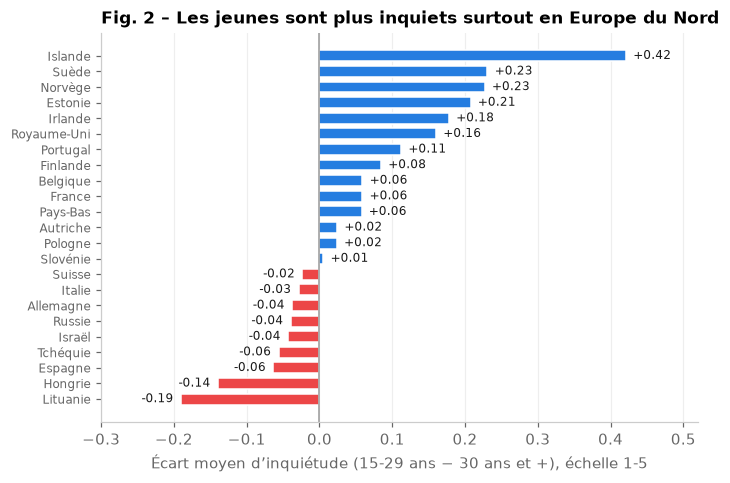

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.6))
cols_ = [BLUE if e > 0 else '#ec4647' for e in gap.ecart]
ax.barh(gap.index, gap.ecart, color=cols_, height=0.7, edgecolor='white', linewidth=1)
ax.axvline(0, color='#999999', lw=1)
for i, e in enumerate(gap.ecart):
    ax.text(e + (0.01 if e > 0 else -0.01), i, f'{e:+.2f}', va='center',
            ha='left' if e > 0 else 'right', fontsize=8, color=TXT)
ax.set_xlim(-0.3, 0.52); ax.grid(axis='y', visible=False)
ax.set_xlabel('Écart moyen d’inquiétude (15-29 ans − 30 ans et +), échelle 1-5')
ax.set_title('Fig. 2 – Les jeunes sont plus inquiets surtout en Europe du Nord')
ax.tick_params(axis='y', labelsize=8)
fig.savefig(FIG / 'fig2_ecart_pays.png'); plt.show()

**Lecture :** la moyenne européenne cache des situations opposées. Dans les pays nordiques et anglo-saxons (Islande, Suède, Norvège, Irlande, Royaume-Uni) et en Estonie, les jeunes sont nettement plus inquiets. En Europe centrale et orientale (Lituanie, Hongrie, Tchéquie) et en Espagne, c'est l'inverse. La France est proche de zéro (+0,06).

## 3. Les jeunes agissent-ils davantage ?

In [11]:
comp_vars = ['eco_energie', 'achat_eff', 'petition', 'manif', 'boycott', 'pour_taxe', 'pour_subv', 'pour_interd']
comp = tableau(comp_vars)
comp_j = tableau(comp_vars, by='jeune'); comp_j.columns = ['30 ans et +', '15-29 ans']
comp_j['écart (pts)'] = (comp_j['15-29 ans'] - comp_j['30 ans et +']) * 100
display(comp * 100)
comp_j

age_grp,15-29,30-44,45-59,60-74,75+
eco_energie,54.295,66.695,72.992,75.795,74.638
achat_eff,45.698,61.210,65.966,68.534,61.135
petition,23.877,26.265,25.102,22.093,13.241
manif,11.465,8.684,9.230,6.765,2.879
boycott,12.968,17.267,19.212,17.740,11.601
pour_taxe,34.527,30.529,28.811,26.457,24.503
pour_subv,76.066,74.065,74.772,70.453,70.638
pour_interd,49.511,57.332,63.190,61.572,59.306


,30 ans et +,15-29 ans,écart (pts)
eco_energie,0.719,0.543,-17.644
achat_eff,0.646,0.457,-18.939
petition,0.234,0.239,0.479
manif,0.077,0.115,3.727
boycott,0.174,0.130,-4.438
pour_taxe,0.283,0.345,6.220
pour_subv,0.730,0.761,3.038
pour_interd,0.606,0.495,-11.050


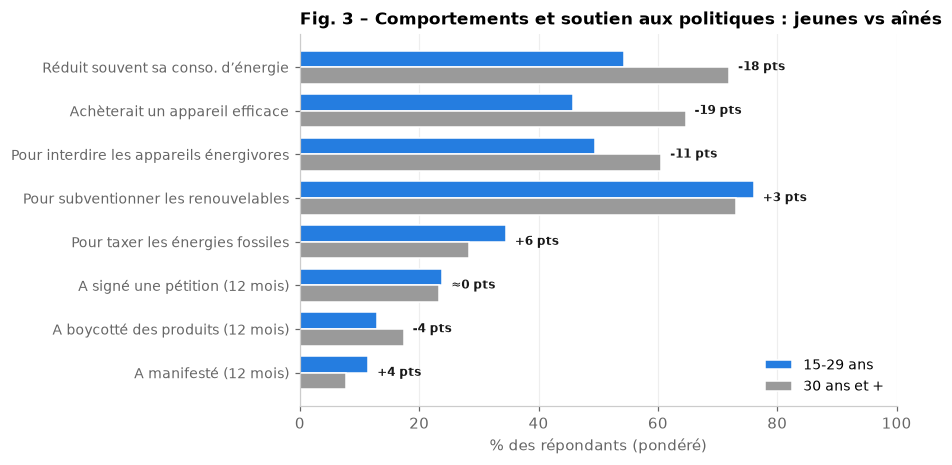

In [12]:
noms = {'eco_energie': 'Réduit souvent sa conso. d’énergie', 'achat_eff': 'Achèterait un appareil efficace',
        'pour_interd': 'Pour interdire les appareils énergivores', 'pour_subv': 'Pour subventionner les renouvelables',
        'pour_taxe': 'Pour taxer les énergies fossiles', 'petition': 'A signé une pétition (12 mois)',
        'boycott': 'A boycotté des produits (12 mois)', 'manif': 'A manifesté (12 mois)'}
ordre = ['eco_energie', 'achat_eff', 'pour_interd', 'pour_subv', 'pour_taxe', 'petition', 'boycott', 'manif'][::-1]
d = comp_j.loc[ordre]
fig, ax = plt.subplots(figsize=(7, 4.4))
y = np.arange(len(d)); h = 0.38
ax.barh(y + h/2, d['15-29 ans'] * 100, h, color=BLUE, label='15-29 ans', edgecolor='white', linewidth=1)
ax.barh(y - h/2, d['30 ans et +'] * 100, h, color=GREY, label='30 ans et +', edgecolor='white', linewidth=1)
for i, (a, b) in enumerate(zip(d['15-29 ans'], d['30 ans et +'])):
    ax.text(max(a, b) * 100 + 1.5, i, f'{(a - b) * 100:+.0f} pts'.replace('+0 ', '≈0 '), va='center', fontsize=8,
            color=TXT, fontweight='bold')
ax.set_yticks(y, [noms[v] for v in ordre], fontsize=9); ax.set_xlim(0, 100)
ax.grid(axis='y', visible=False); ax.set_xlabel('% des répondants (pondéré)')
ax.set_title('Fig. 3 – Comportements et soutien aux politiques : jeunes vs aînés')
ax.legend(frameon=False, loc='lower right', fontsize=9)
fig.savefig(FIG / 'fig3_comportements.png'); plt.show()

In [13]:
res_comp = pd.DataFrame({y: effet_jeune(y) for y in comp_vars}).T
res_comp

,coef_jeune,IC95_bas,IC95_haut,p_value,n
eco_energie,-0.142,-0.153,-0.130,0.000,43312.000
achat_eff,-0.171,-0.183,-0.159,0.000,42788.000
petition,0.011,0.001,0.021,0.025,43661.000
manif,0.025,0.018,0.031,0.000,43712.000
boycott,-0.032,-0.040,-0.023,0.000,43635.000
pour_taxe,0.041,0.030,0.053,0.000,41941.000
pour_subv,0.016,0.005,0.026,0.003,42508.000
pour_interd,-0.071,-0.083,-0.059,0.000,42235.000


**Lecture :** le tableau est contrasté.
- **Gestes du quotidien : les jeunes font moins.** Ils sont nettement moins nombreux à réduire souvent leur consommation d'énergie et à se dire prêts à acheter un appareil économe. Ils sont aussi moins favorables à l'interdiction des appareils énergivores.
- **Engagement politique et taxe carbone : les jeunes font plus.** Ils manifestent davantage et soutiennent plus la taxation des énergies fossiles ; ils signent autant de pétitions, mais boycottent un peu moins.

Une partie de l'écart sur les gestes quotidiens relève sans doute de la **situation de vie** plutôt que des convictions : beaucoup de jeunes vivent chez leurs parents ou en colocation, ne paient pas les factures et n'achètent pas d'électroménager. On vérifie en contrôlant le statut d'étudiant :

In [14]:
pd.DataFrame({'sans contrôle étudiant': res_comp.loc[['eco_energie', 'achat_eff'], 'coef_jeune'],
              'avec contrôle étudiant': [effet_jeune(y, ' + etudiant')['coef_jeune'] for y in ['eco_energie', 'achat_eff']]})

,sans contrôle étudiant,avec contrôle étudiant
eco_energie,-0.142,-0.137
achat_eff,-0.171,-0.150


L'écart ne diminue presque pas (−14,2 → −13,7 pts pour les économies d'énergie, −17,1 → −15,0 pts pour les achats) : le statut d'étudiant n'explique qu'une faible part de la différence. D'autres facteurs de « cycle de vie » non mesurés ici (vivre chez ses parents, ne pas payer les factures) peuvent jouer.

## 4. L'inquiétude se traduit-elle en actes ?

On regarde la part de personnes qui adoptent chaque comportement selon leur niveau d'inquiétude, séparément pour les jeunes et les aînés.

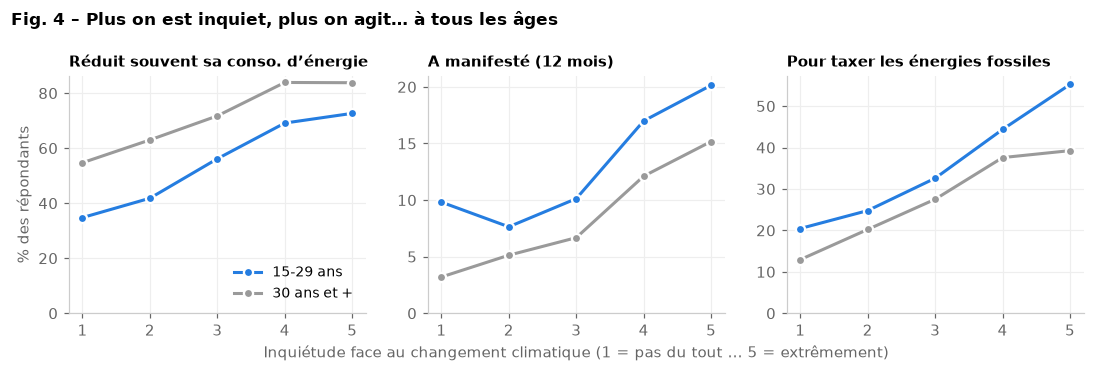

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharex=True)
for ax, (v, titre) in zip(axes, [('eco_energie', 'Réduit souvent sa conso. d’énergie'),
                                 ('manif', 'A manifesté (12 mois)'),
                                 ('pour_taxe', 'Pour taxer les énergies fossiles')]):
    t = df.dropna(subset=['wrclmch', v]).groupby(['jeune', 'wrclmch']).apply(lambda g: wmean(g, v)).unstack(0) * 100
    ax.plot(t.index, t[1], color=BLUE, lw=2, marker='o', ms=6, mec='white', mew=1.5, label='15-29 ans')
    ax.plot(t.index, t[0], color=GREY, lw=2, marker='o', ms=6, mec='white', mew=1.5, label='30 ans et +')
    ax.set_title(titre, fontsize=10); ax.set_xticks([1, 2, 3, 4, 5])
    ax.set_ylim(0, None)
axes[0].set_ylabel('% des répondants')
axes[1].set_xlabel('Inquiétude face au changement climatique (1 = pas du tout … 5 = extrêmement)')
axes[0].legend(frameon=False, fontsize=9, loc='lower right')
fig.suptitle('Fig. 4 – Plus on est inquiet, plus on agit… à tous les âges', x=0.01, ha='left',
             fontweight='bold', fontsize=11)
fig.tight_layout(); fig.savefig(FIG / 'fig4_inquietude_action.png'); plt.show()

### Régression avec interaction inquiétude × jeune
Modèle de probabilité linéaire : `comportement ~ inquiétude × jeune + sexe + éducation + effets fixes pays`.
- `wrclmch` : effet d'un point d'inquiétude supplémentaire chez les 30 ans et + (en proportion) ;
- `wrclmch:jeune` : effet **supplémentaire** chez les jeunes (positif = le lien inquiétude → action est plus fort chez les jeunes).

In [16]:
rows = {}
for y in comp_vars:
    r = smf.ols(f'{y} ~ wrclmch * jeune + femme + eduyrs + C(cntry)', data=df).fit(cov_type='HC1')
    rows[y] = {'effet inquiétude (30+)': r.params['wrclmch'],
               'effet inquiétude (15-29)': r.params['wrclmch'] + r.params['wrclmch:jeune'],
               'différence': r.params['wrclmch:jeune'], 'p diff.': r.pvalues['wrclmch:jeune'],
               'R²': r.rsquared}
res_inter = pd.DataFrame(rows).T
res_inter

,effet inquiétude (30+),effet inquiétude (15-29),différence,p diff.,R²
eco_energie,0.074,0.094,0.021,0.001,0.067
achat_eff,0.067,0.064,-0.004,0.570,0.084
petition,0.048,0.058,0.010,0.073,0.136
manif,0.021,0.032,0.011,0.006,0.054
boycott,0.049,0.056,0.007,0.144,0.148
pour_taxe,0.076,0.098,0.022,0.000,0.092
pour_subv,0.058,0.068,0.010,0.067,0.065
pour_interd,0.089,0.087,-0.002,0.755,0.065


**Lecture :** pour **tous** les comportements, l'inquiétude est associée positivement à l'action, chez les jeunes comme chez les aînés : un point d'inquiétude en plus (sur 5) correspond à environ +7 points de % de chances de réduire souvent sa consommation d'énergie et +5 points pour signer une pétition. Le lien est **même un peu plus fort chez les jeunes** (différence significative à 1 %) pour les économies d'énergie, la manifestation et le soutien à la taxe sur les énergies fossiles. L'inquiétude n'est donc pas « déclarative » chez les jeunes : quand elle est présente, elle se traduit autant (voire plus) en actes. Les R² restent cependant faibles : l'inquiétude n'explique qu'une petite partie des comportements.

## 5. Conclusion

1. **En 2016, les jeunes Européens ne sont pas globalement plus inquiets** que leurs aînés (≈ 30 % très/extrêmement inquiets à tous les âges avant 75 ans). L'écart existe dans certains pays (Nord de l'Europe) et s'inverse dans d'autres (Europe centrale et orientale).
2. Ils se distinguent par une **meilleure acceptation de l'origine humaine** du changement climatique.
3. **Côté comportements**, ils font **moins de gestes individuels** (énergie, achats) mais sont **plus engagés politiquement** (manifestations, soutien à la taxe sur les énergies fossiles).
4. **L'inquiétude se traduit bien en comportements, à tous les âges**, et un peu plus fortement chez les jeunes.

**Limites :** données de 2016, *avant* les grèves pour le climat de 2018-2019 ; données en coupe transversale, qui ne permettent pas de séparer effet d'âge (cycle de vie) et effet de génération ; comportements **déclarés** ; manifestation, pétition et boycott ne sont pas spécifiquement climatiques ; modèles linéaires simples.